# 06 Model comparison and statistics

Each held-out day is one block (N = 22). Tests follow Demšar (2006): Friedman with the Iman-Davenport correction, Nemenyi critical difference, Holm against the best-ranked model, and Wilcoxon signed-rank tests for pre-specified pairs. No retraining; inputs are the saved predictions of notebooks 03 to 05.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from src.config import DATA_PROC, RESULTS, SEED
from src.metrics import summarise, non_monotone_share
from src import style

style.apply()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

PRED = RESULTS / "predictions"
MET = RESULTS / "metrics"
DIRECT = ["sed_mean", "linear", "ridge_poly", "svr", "rf", "et", "hgb", "mlp", "gp", "tabpfn"]
REGS = ["linear", "ridge_poly", "svr", "et", "mlp"]
HYB = [f"hyb_san_{r}" for r in REGS]
HYB_F = [f"hyb_san_floor_{r}" for r in REGS]
rng = np.random.default_rng(SEED)


def holm(p):
    p = np.asarray(p, float)
    o = np.argsort(p)
    adj = np.maximum.accumulate((len(p) - np.arange(len(p))) * p[o]).clip(max=1)
    out = np.empty_like(p)
    out[o] = adj
    return out


def boot_ci(x, n=5000):
    x = np.asarray(x)
    return np.percentile(rng.choice(x, (n, len(x))).mean(1), [2.5, 97.5])

## 1. Scores with 95 % bootstrap CIs over days

In [2]:
cols = ["model", "fset", "split", "run", "day", "sed", "t0_raw", "log_turb", "pred"]
files = [f for d in ("03", "04", "05") for f in sorted((PRED / d).glob("*.csv")) if not f.name.startswith("params")]
allp = pd.concat([pd.read_csv(f)[cols] for f in files], ignore_index=True)
oracle = allp[allp["model"].str.startswith("oracle")]
preds = allp[~allp["model"].str.startswith("oracle")]

rows, by_day = [], {}
for key, g in preds.groupby(["fset", "split", "model"]):
    s, d = summarise(g)
    lo, hi = boot_ci(d)
    rows.append(dict(zip(["fset", "split", "model"], key), day_rmse=s["day_rmse_mean"], ci_lo=lo, ci_hi=hi,
                     r2_log=s["r2_log"], rise_share=non_monotone_share(g)))
    by_day[key] = d
score = pd.DataFrame(rows).set_index(["fset", "split", "model"]).sort_index()
days = pd.DataFrame(by_day)
for key, g in oracle.groupby("model"):
    print(key, "day RMSE:", round(summarise(g)[0]["day_rmse_mean"], 4))
score.loc[("core", "lodo")].sort_values("day_rmse").round(4)

oracle_san day RMSE: 0.0236
oracle_san_floor day RMSE: 0.019


,day_rmse,ci_lo,ci_hi,r2_log,rise_share
model,,,,,
hyb_san_svr,0.1376,0.1086,0.1716,0.6838,0.0000
hyb_san_floor_linear,0.1392,0.1081,0.1737,0.6856,0.0000
mlp,0.1396,0.1089,0.1756,0.6762,0.0238
hyb_san_ridge_poly,0.1412,0.1119,0.1758,0.6703,0.0000
ridge_poly,0.1417,0.1102,0.1779,0.6718,0.0060
svr,0.1418,0.1107,0.1762,0.6781,0.0000
hyb_san_floor_ridge_poly,0.1442,0.1121,0.1806,0.6642,0.0000
hyb_san_floor_svr,0.1478,0.1155,0.1842,0.6478,0.0000
hyb_san_mlp,0.1478,0.1181,0.1822,0.6570,0.0000


## 2. Friedman test and Nemenyi critical difference (core, leave-one-day-out)

In [3]:
def friedman(D, alpha=0.05):
    N, k = D.shape
    R = D.rank(axis=1).mean().sort_values()
    chi2 = 12 * N / (k * (k + 1)) * ((R ** 2).sum() - k * (k + 1) ** 2 / 4)
    ff = (N - 1) * chi2 / (N * (k - 1) - chi2)
    p = stats.f.sf(ff, k - 1, (k - 1) * (N - 1))
    se = np.sqrt(k * (k + 1) / (6 * N))
    cd = stats.studentized_range.ppf(1 - alpha, k, np.inf) / np.sqrt(2) * se
    z = (R - R.iloc[0]) / se
    p_ctrl = 2 * stats.norm.sf(z.iloc[1:])
    ctrl = pd.DataFrame({"mean_rank": R, "p_vs_best": np.r_[np.nan, p_ctrl], "p_holm": np.r_[np.nan, holm(p_ctrl)]})
    return ctrl, dict(N=N, k=k, chi2=chi2, F=ff, p=p, cd=cd)


D = days[("core", "lodo")][DIRECT + HYB]
fried, fr = friedman(D)
print(f"N = {fr['N']} days, k = {fr['k']} models | chi2_F = {fr['chi2']:.1f}, F_F = {fr['F']:.2f}, p = {fr['p']:.2e} | CD = {fr['cd']:.2f}")
fried.round(4)

N = 22 days, k = 15 models | chi2_F = 65.3, F_F = 5.65, p = 1.04e-09 | CD = 4.57


,mean_rank,p_vs_best,p_holm
svr,6.0000,NaN,NaN
hyb_san_ridge_poly,6.0909,0.9462,1.0000
hyb_san_svr,6.1364,0.9194,1.0000
mlp,6.3182,0.8135,1.0000
ridge_poly,6.4091,0.7616,1.0000
hyb_san_linear,7.4091,0.2960,1.0000
hyb_san_mlp,7.5000,0.2660,1.0000
hyb_san_et,7.5455,0.2517,1.0000
linear,8.0000,0.1380,1.0000
hgb,8.2273,0.0986,0.8872


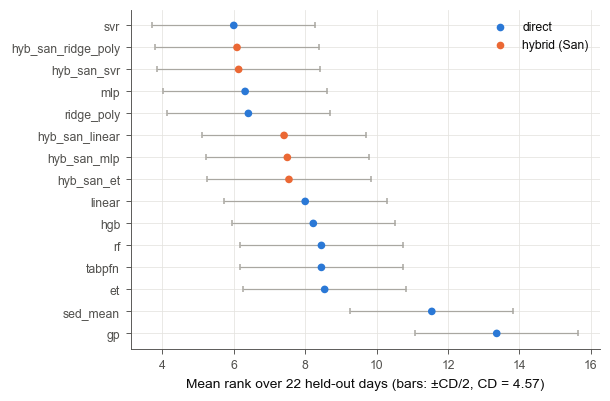

In [4]:
fig, ax = plt.subplots(figsize=(5.5, 4))
y = np.arange(len(fried))[::-1]
col = [style.COLORS[1] if m.startswith("hyb") else style.COLORS[0] for m in fried.index]
ax.errorbar(fried["mean_rank"], y, xerr=fr["cd"] / 2, fmt="none", ecolor=style.MUTED, capsize=2, lw=0.8)
ax.scatter(fried["mean_rank"], y, c=col, zorder=3)
ax.set_yticks(y, fried.index)
ax.set_xlabel(f"Mean rank over {fr['N']} held-out days (bars: ±CD/2, CD = {fr['cd']:.2f})")
ax.scatter([], [], c=style.COLORS[0], label="direct")
ax.scatter([], [], c=style.COLORS[1], label="hybrid (San)")
ax.legend(loc="upper right")
style.save(fig, "fig01_friedman_ranks", "stats")
plt.show()

## 3. Pre-specified paired comparisons (Wilcoxon signed-rank, Holm)

In [5]:
def paired(D, pairs):
    out = []
    for a, b in pairs:
        d = D[a] - D[b]
        out.append({"a": a, "b": b, "mean_diff": d.mean(), "median_diff": d.median(),
                    "a_wins": int((d < 0).sum()), "p": stats.wilcoxon(D[a], D[b]).pvalue})
    out = pd.DataFrame(out)
    out["p_holm"] = holm(out["p"])
    return out


Dc = days[("core", "lodo")]
pairs = [(f"hyb_san_{r}", r) for r in REGS] + [(f"hyb_san_floor_{r}", f"hyb_san_{r}") for r in REGS]
pair_tab = paired(Dc, pairs)
pair_tab.round(4)

,a,b,mean_diff,median_diff,a_wins,p,p_holm
0,hyb_san_linear,linear,-0.0000,-0.0007,12,0.9493,1.0000
1,hyb_san_ridge_poly,ridge_poly,-0.0006,-0.0014,12,0.4434,1.0000
2,hyb_san_svr,svr,-0.0042,0.0015,11,0.8486,1.0000
3,hyb_san_et,et,-0.0062,-0.0057,15,0.0634,0.5708
4,hyb_san_mlp,mlp,0.0082,0.0087,8,0.1055,0.7382
5,hyb_san_floor_linear,hyb_san_linear,-0.0117,-0.0128,17,0.0301,0.3012
6,hyb_san_floor_ridge_poly,hyb_san_ridge_poly,0.0030,0.0054,10,0.1982,1.0000
7,hyb_san_floor_svr,hyb_san_svr,0.0101,0.0079,8,0.0794,0.6354
8,hyb_san_floor_et,hyb_san_et,-0.0006,-0.0028,14,0.6102,1.0000
9,hyb_san_floor_mlp,hyb_san_mlp,0.0063,0.0006,11,0.8987,1.0000


## 4. Random split versus leave-one-day-out

In [6]:
rv = pd.DataFrame({"random": score.loc[("core", "random"), "day_rmse"],
                   "lodo": score.loc[("core", "lodo"), "day_rmse"]}).loc[DIRECT]
rv["ratio"] = rv["lodo"] / rv["random"]
rv["rank_random"] = rv["random"].rank()
rv["rank_lodo"] = rv["lodo"].rank()
rho = stats.spearmanr(rv["random"], rv["lodo"])
print(f"Spearman rank correlation, random vs LODO: rho = {rho.statistic:.2f}, p = {rho.pvalue:.3f}")
rv.sort_values("lodo").round(4)

Spearman rank correlation, random vs LODO: rho = -0.38, p = 0.276


,random,lodo,ratio,rank_random,rank_lodo
model,,,,,
mlp,0.1257,0.1396,1.1110,6.0,1.0
ridge_poly,0.1281,0.1417,1.1066,8.0,2.0
svr,0.1265,0.1418,1.1209,7.0,3.0
linear,0.1440,0.1509,1.0482,9.0,4.0
hgb,0.0417,0.1555,3.7270,3.0,5.0
rf,0.0777,0.1570,2.0208,4.0,6.0
et,0.0848,0.1574,1.8557,5.0,7.0
tabpfn,0.0231,0.1592,6.8898,1.0,8.0
sed_mean,0.2539,0.2616,1.0304,10.0,9.0


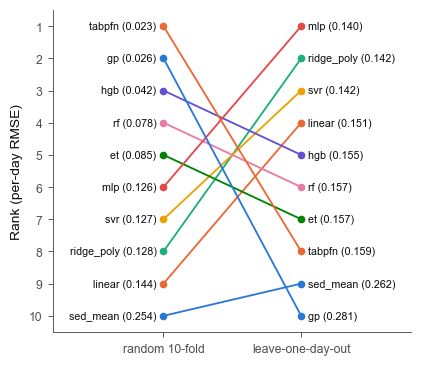

In [7]:
fig, ax = plt.subplots(figsize=(4.2, 3.8))
for i, (m, r) in enumerate(rv.iterrows()):
    c = style.COLORS[i % len(style.COLORS)]
    ax.plot([0, 1], [r["rank_random"], r["rank_lodo"]], "o-", color=c)
    ax.text(-0.05, r["rank_random"], f"{m} ({r['random']:.3f})", ha="right", va="center", fontsize=7)
    ax.text(1.05, r["rank_lodo"], f"{m} ({r['lodo']:.3f})", ha="left", va="center", fontsize=7)
ax.set_xlim(-0.8, 1.8)
ax.set_ylim(len(rv) + 0.5, 0.5)
ax.set_xticks([0, 1], ["random 10-fold", "leave-one-day-out"])
ax.set_yticks(range(1, len(rv) + 1))
ax.set_ylabel("Rank (per-day RMSE)")
ax.grid(False)
style.save(fig, "fig02_random_vs_lodo", "stats")
plt.show()

## 5. Full versus core features

A held-out day counts as *seen* when all of its (speed, mixing time) settings also occur on other days.

In [8]:
long = pd.read_csv(DATA_PROC / "long.csv")
sets = long.drop_duplicates(["day", "speed", "mtime"]).groupby("day").apply(
    lambda g: set(zip(g["speed"], g["mtime"])), include_groups=False)
seen = pd.Series({d: s <= set().union(*sets.drop(d)) for d, s in sets.items()}, name="seen")
print(f"seen days: {seen.sum()}, unseen days: {(~seen).sum()}")

models_full = [m for m in DIRECT[1:] + HYB + HYB_F if ("full", "lodo", m) in days]
fc = paired(pd.concat({f"{m}|core": days[("core", "lodo", m)] for m in models_full} |
                      {f"{m}|full": days[("full", "lodo", m)] for m in models_full}, axis=1),
            [(f"{m}|full", f"{m}|core") for m in models_full])
fc.insert(0, "model", fc.pop("a").str.split("|").str[0])
fc = fc.drop(columns="b")

gain = pd.DataFrame({m: days[("core", "lodo", m)] - days[("full", "lodo", m)] for m in models_full})
fc["gain_seen"] = gain[seen].mean().values
fc["gain_unseen"] = gain[~seen].mean().values
day_gain = gain.mean(axis=1)
mw = stats.mannwhitneyu(day_gain[seen], day_gain[~seen])
print(f"mean gain over models, seen vs unseen days: Mann-Whitney U = {mw.statistic:.0f}, p = {mw.pvalue:.3f}")
fc.round(4)

seen days: 14, unseen days: 8
mean gain over models, seen vs unseen days: Mann-Whitney U = 57, p = 0.973


,model,mean_diff,median_diff,a_wins,p,p_holm,gain_seen,gain_unseen
0,linear,-0.0210,-0.0162,13,0.0794,0.9531,0.0194,0.0239
1,ridge_poly,-0.0047,-0.0153,14,0.5661,1.0000,0.0037,0.0064
2,svr,-0.0189,-0.0192,14,0.0984,1.0000,0.0162,0.0235
3,rf,-0.0215,-0.0144,15,0.0301,0.3915,0.0114,0.0391
4,et,-0.0381,-0.0197,19,0.0007,0.0125,0.0358,0.0421
5,hgb,-0.0274,-0.0189,18,0.0009,0.0151,0.0179,0.0440
6,mlp,0.0202,0.0047,10,0.9240,1.0000,0.0037,-0.0620
7,gp,-0.0512,-0.0381,19,0.0017,0.0251,0.0555,0.0438
8,tabpfn,-0.0378,-0.0124,18,0.0007,0.0125,0.0378,0.0377
9,hyb_san_linear,-0.0184,-0.0087,13,0.1289,1.0000,0.0192,0.0169


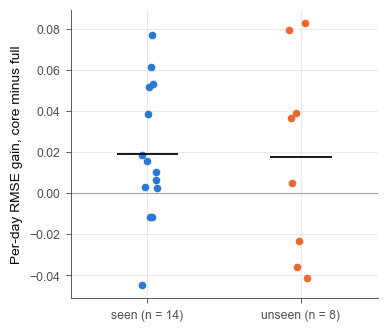

In [9]:
fig, ax = plt.subplots(figsize=(3.6, 3.4))
for i, (lab, mask) in enumerate([("seen", seen), ("unseen", ~seen)]):
    v = day_gain[mask]
    ax.scatter(np.full(len(v), i) + rng.uniform(-0.08, 0.08, len(v)), v, color=style.COLORS[i])
    ax.hlines(v.mean(), i - 0.2, i + 0.2, color=style.INK)
ax.axhline(0, color=style.MUTED, lw=0.8)
ax.set_xticks([0, 1], [f"seen (n = {seen.sum()})", f"unseen (n = {(~seen).sum()})"])
ax.set_xlim(-0.5, 1.5)
ax.set_ylabel("Per-day RMSE gain, core minus full")
style.save(fig, "fig03_full_gain_seen_unseen", "stats")
plt.show()

## 6. Prediction intervals (core, leave-one-day-out)

Day-wise residual intervals: for each held-out day, the half-width is the 90 % quantile of absolute residuals from the other 21 days. TabPFN quantiles shown for comparison. Coverage is averaged over days.

In [10]:
def residual_interval(g, level=0.9):
    g = g.assign(res=(g["log_turb"] - g["pred"]).abs())
    rows = []
    for d, gd in g.groupby("day"):
        r = g.loc[g["day"] != d, "res"].to_numpy()
        q = np.quantile(r, min(1, np.ceil((len(r) + 1) * level) / len(r)))
        rows.append({"day": d, "cover": (gd["res"] <= q).mean(), "width": 2 * q})
    return pd.DataFrame(rows)


core = preds[(preds["fset"] == "core") & (preds["split"] == "lodo")]
iv = {m: residual_interval(core[core["model"] == m]) for m in ["hyb_san_svr", "mlp", "svr", "tabpfn"]}
tp = pd.read_csv(PRED / "04" / "tabpfn__core__lodo.csv")
tp_cov = ((tp["log_turb"] >= tp["q05"]) & (tp["log_turb"] <= tp["q95"])).groupby(tp["day"]).mean()
iv_tab = pd.DataFrame({m: {"coverage": d["cover"].mean(), "min_day_coverage": d["cover"].min(),
                           "width_log": d["width"].mean()} for m, d in iv.items()}).T
iv_tab.loc["tabpfn_quantiles"] = [tp_cov.mean(), tp_cov.min(), (tp["q95"] - tp["q05"]).mean()]
iv_tab.round(3)

,coverage,min_day_coverage,width_log
hyb_san_svr,0.894,0.139,0.524
mlp,0.886,0.139,0.532
svr,0.883,0.083,0.525
tabpfn,0.894,0.333,0.577
tabpfn_quantiles,0.825,0.306,0.504


## 7. Save

In [11]:
score.round(5).to_csv(MET / "06_scores_ci.csv")
fried.round(5).to_csv(MET / "06_friedman_core_lodo.csv")
pair_tab.round(5).to_csv(MET / "06_paired_tests.csv", index=False)
rv.round(5).to_csv(MET / "06_random_vs_lodo.csv")
fc.round(5).to_csv(MET / "06_full_vs_core.csv", index=False)
iv_tab.round(5).to_csv(MET / "06_intervals.csv")

key = {
    "friedman": {k: float(f"{v:.4g}") for k, v in fr.items()},
    "best_ranked": fried.index[0],
    "not_different_from_best_holm": fried.index[1:][fried["p_holm"].iloc[1:] > 0.05].tolist(),
    "spearman_random_vs_lodo": round(float(rho.statistic), 3),
    "seen_days": int(seen.sum()),
    "gain_seen_vs_unseen_p": round(float(mw.pvalue), 4),
}
(MET / "06_key_numbers.json").write_text(json.dumps(key, indent=2))
key

{'friedman': {'N': 22.0,
  'k': 15.0,
  'chi2': 65.32,
  'F': 5.653,
  'p': 1.042e-09,
  'cd': 4.573},
 'best_ranked': 'svr',
 'not_different_from_best_holm': ['hyb_san_ridge_poly',
  'hyb_san_svr',
  'mlp',
  'ridge_poly',
  'hyb_san_linear',
  'hyb_san_mlp',
  'hyb_san_et',
  'linear',
  'hgb',
  'rf',
  'tabpfn',
  'et'],
 'spearman_random_vs_lodo': -0.382,
 'seen_days': 14,
 'gain_seen_vs_unseen_p': 0.9734}